# Fase 4 — Modelagem

**Projeto:** Supply Chain Forecasting — Rede Bandeirante (CD de Jundiaí)
**Produto foco:** P0131 (mercearia seca) · **Horizonte:** H = 28 dias (lead time 14 + ciclo de revisão 14)

## Objetivo
Construir e comparar cinco modelos de previsão de demanda diária para o P0131, avaliados
numa **única janela de teste (holdout) de 28 dias**, no corte temporal definido na Fase 3:
treino até **03/10/2019** e teste de **04/10/2019 a 31/10/2019**. O baseline é o processo
atual do comprador — a média das últimas 4 semanas (MM28).

## Métricas
- **WMAPE** = Σ|previsto − real| / Σ real × 100 (menor é melhor)
- **Viés** = Σ(previsto − real) / Σ real × 100 (próximo de zero é o desejado)
- Toda previsão é **clipada em zero** antes de medir.

## Modelos avaliados
1. **Naive Sazonal** — repete os últimos 7 dias do treino.
2. **Média Móvel 28d (MM28)** — baseline do comprador.
3. **Holt-Winters** — tendência e sazonalidade aditivas, período 7.
4. **SARIMA** (2,1,2)(1,1,1,7).
5. **SARIMAX + promo** — SARIMA com a exógena `pct_lojas_promo` e tendência `'ct'`.

## Resumo dos achados
Nesta janela única, o **SARIMAX + promo** venceu, com **WMAPE 8,41%** e **viés +0,50%**
(praticamente sem viés), superando o baseline do comprador (MM28: **17,18%** / +3,79%) e o
Holt-Winters (**9,30%** / −3,82%). Naive Sazonal: 10,17% / −1,84%; SARIMA: 13,47% / +11,11%.
A demanda real do período foi **8.158 unidades**; o SARIMAX+promo previu ~**8.199 unidades**.

> **Regra de ouro:** nunca embaralhar a série (dados em ordem temporal); o teste é sempre o
> futuro do treino. `SEED = 42`.

In [1]:
# ======================================================================
# 4.0 — Setup, carga dos dados e corte temporal
# ======================================================================

%matplotlib inline
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")

# Caminhos relativos a raiz do projeto (localizada automaticamente)
from pathlib import Path


def _encontrar_raiz():
    """Sobe diretorios ate achar a raiz do projeto (que contem data/raw/demanda.csv)."""
    p = Path.cwd()
    for _ in range(6):
        if (p / "data" / "raw" / "demanda.csv").exists():
            return p
        p = p.parent
    return Path.cwd()


RAIZ = _encontrar_raiz()
CAMINHO_REDE = str(RAIZ / "data" / "raw" / "demanda.csv")
PASTA_FIGURAS = str(RAIZ / "reports" / "figures")
os.makedirs(PASTA_FIGURAS, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.05)

# --- Parametros do case ---
H = 28                                            # horizonte: lead time 14 + ciclo de revisao 14
PRODUTO_FOCO = "P0131"
PRODUTOS_REMOVER = ["P0438", "P0051", "P0079"]    # itens fora do escopo (regra da Fase 3)

# --- Carregamento e filtro (mesma regra da Fase 3) ---
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)
df_limpo = df[~df["produto"].isin(PRODUTOS_REMOVER)].copy().reset_index(drop=True)

serie_p = (
    df_limpo[df_limpo["produto"] == PRODUTO_FOCO]
    .sort_values("data")
    .set_index("data")
    .asfreq("D")
)

# --- Corte temporal: treino ate 03/10/2019; teste 04/10 a 31/10/2019 (28 dias) ---
data_maxima = serie_p.index.max()
data_corte = data_maxima - pd.Timedelta(days=H)
data_inicio_teste = data_corte + pd.Timedelta(days=1)
treino_p = serie_p.loc[:data_corte]
teste_p = serie_p.loc[data_inicio_teste:]

real = teste_p["unidades"].astype(float).values
indice_teste = teste_p.index
serie_treino_ord = treino_p.sort_index()["unidades"].astype(float)

print("FASE 4 — Modelagem")
print("=" * 70)
print("INFRAESTRUTURA DE AVALIACAO INICIALIZADA")
print("-" * 70)
print("  Horizonte de previsao (H) : {} dias".format(H))
print("  Periodo de treino         : {:%d/%m/%Y} -> {:%d/%m/%Y}  (n={})".format(
    treino_p.index.min(), treino_p.index.max(), len(treino_p)))
print("  Periodo de teste          : {:%d/%m/%Y} -> {:%d/%m/%Y}  (n={} dias)".format(
    indice_teste.min(), indice_teste.max(), len(indice_teste)))
print("  Produto                   : {}".format(PRODUTO_FOCO))
print("  Demanda real TOTAL do teste : {:,.2f} unidades".format(float(np.sum(real))))
print("  Demanda real MEDIA por dia   : {:,.2f} unidades/dia".format(float(np.mean(real))))

FASE 4 — Modelagem
INFRAESTRUTURA DE AVALIACAO INICIALIZADA
----------------------------------------------------------------------
  Horizonte de previsao (H) : 28 dias
  Periodo de treino         : 02/01/2017 -> 03/10/2019  (n=1005)
  Periodo de teste          : 04/10/2019 -> 31/10/2019  (n=28 dias)
  Produto                   : P0131
  Demanda real TOTAL do teste : 8,158.00 unidades
  Demanda real MEDIA por dia   : 291.36 unidades/dia


### 4.1 — Infraestrutura de avaliação
Funções `wmape()` e `vies()` e a função `avaliar()`, que aplica o clip em zero e registra
resultados nos dicionários `placar` e `previsoes`.

In [2]:
# --- Metricas de avaliacao ---
def wmape(real, previsto):
    """WMAPE = soma|previsto - real| / soma(real) * 100."""
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)
    return 100.0 * np.sum(np.abs(previsto - real)) / np.sum(real)


def vies(real, previsto):
    """Vies = soma(previsto - real) / soma(real) * 100 (+ superestima, - subestima)."""
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)
    return 100.0 * np.sum(previsto - real) / np.sum(real)


# Estado global: placar (metricas) e previsoes (series)
placar = {}
previsoes = {}


def avaliar(nome, previsao_raw):
    """Clipa a previsao em zero, mede WMAPE e Vies e guarda em placar/previsoes."""
    if isinstance(previsao_raw, pd.DataFrame):
        arr = previsao_raw["unidades"].astype(float).values
    elif isinstance(previsao_raw, pd.Series):
        arr = previsao_raw.astype(float).values
    else:
        arr = np.asarray(previsao_raw, dtype=float)

    prev_clip = np.clip(arr, a_min=0.0, a_max=None)   # clip em zero ANTES de medir

    w = wmape(real, prev_clip)
    v = vies(real, prev_clip)

    placar[nome] = {
        "WMAPE_%": round(w, 4),
        "Vies_%": round(v, 4),
        "Demanda_prevista_total": round(float(np.sum(prev_clip)), 2),
        "Demanda_real_total": round(float(np.sum(real)), 2),
    }
    previsoes[nome] = pd.Series(prev_clip, index=indice_teste, name="prev_" + nome)

    sinal = "+" if v >= 0 else ""
    print("  {:40s} | WMAPE = {:6.3f}% | Vies = {}{:6.3f}% | Previsto = {:>9,.1f}".format(
        nome, w, sinal, v, placar[nome]["Demanda_prevista_total"]))
    return w, v

print("Funcoes wmape(), vies() e avaliar() definidas.")
print("  WMAPE = soma|prev - real| / soma(real) x 100")
print("  Vies  = soma(prev - real) / soma(real) x 100   (+ superestima, - subestima)")

Funcoes wmape(), vies() e avaliar() definidas.
  WMAPE = soma|prev - real| / soma(real) x 100
  Vies  = soma(prev - real) / soma(real) x 100   (+ superestima, - subestima)


### 4.2 — Modelo 1: Naive Sazonal
Repete os últimos 7 dias do treino (um ciclo semanal) ao longo dos 28 dias do teste.

In [3]:
print("MODELO 1 — NAIVE SAZONAL (repete os ultimos 7 dias do treino)")
print("-" * 70)
ultimos_7 = serie_treino_ord.tail(7).values.copy()
previsao_naive = np.tile(ultimos_7, reps=int(np.ceil(H / 7)))[:H]
print("  Template (ultimos 7 dias do treino): {}".format(np.round(ultimos_7, 0).astype(int).tolist()))
print("  Periodo previsto: {:%d/%m/%Y} -> {:%d/%m/%Y} ({} dias)".format(
    indice_teste.min(), indice_teste.max(), H))
w_naive, v_naive = avaliar("Naive Sazonal (ultimos 7d)", previsao_naive)

MODELO 1 — NAIVE SAZONAL (repete os ultimos 7 dias do treino)
----------------------------------------------------------------------
  Template (ultimos 7 dias do treino): [296, 327, 351, 273, 244, 271, 240]
  Periodo previsto: 04/10/2019 -> 31/10/2019 (28 dias)
  Naive Sazonal (ultimos 7d)               | WMAPE = 10.174% | Vies = -1.839% | Previsto =   8,008.0


### 4.3 — Modelo 2: Média Móvel 28d (baseline do comprador)
Média simples das últimas 4 semanas, repetida em todos os dias do horizonte.

In [4]:
print("MODELO 2 — MEDIA MOVEL 28d (baseline do comprador)")
print("-" * 70)
media_28d = serie_treino_ord.tail(28).mean()
previsao_mm28 = np.repeat(media_28d, H)
print("  Media das ultimas 4 semanas: {:,.2f} unidades/dia (repetida em todos os dias)".format(media_28d))
print("  Obs.: a MM28 ignora a sazonalidade semanal e nao extrapola tendencia.")
w_mm28, v_mm28 = avaliar("Media Movel 28d (baseline comprador)", previsao_mm28)

MODELO 2 — MEDIA MOVEL 28d (baseline do comprador)
----------------------------------------------------------------------
  Media das ultimas 4 semanas: 302.39 unidades/dia (repetida em todos os dias)
  Obs.: a MM28 ignora a sazonalidade semanal e nao extrapola tendencia.
  Media Movel 28d (baseline comprador)     | WMAPE = 17.175% | Vies = + 3.788% | Previsto =   8,467.0


### 4.4 — Modelo 3: Holt-Winters
Suavização exponencial com tendência (`add`) e sazonalidade (`add`) de período 7.

In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

print("MODELO 3 — HOLT-WINTERS (trend='add', seasonal='add', periodos=7)")
print("-" * 70)
modelo_hw = ExponentialSmoothing(
    serie_treino_ord, trend="add", seasonal="add", seasonal_periods=7,
    initialization_method="estimated", freq="D",
)
ajuste_hw = modelo_hw.fit(optimized=True)
previsao_hw = ajuste_hw.forecast(H).values

alpha = ajuste_hw.params["smoothing_level"]
beta = ajuste_hw.params["smoothing_trend"]
gamma = ajuste_hw.params["smoothing_seasonal"]
print("  Parametros estimados: alfa={:.4f}  beta={:.4f}  gama={:.4f}".format(alpha, beta, gamma))
w_hw, v_hw = avaliar("Holt-Winters (add/add, periodo 7)", previsao_hw)

MODELO 3 — HOLT-WINTERS (trend='add', seasonal='add', periodos=7)
----------------------------------------------------------------------


  Parametros estimados: alfa=0.4953  beta=0.0000  gama=0.0260
  Holt-Winters (add/add, periodo 7)        | WMAPE =  9.303% | Vies = -3.821% | Previsto =   7,846.3


### 4.5 — Modelo 4: SARIMA (2,1,2)(1,1,1,7)
SARIMA sem variáveis exógenas, `trend=None` (padrão).

In [6]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("MODELO 4 — SARIMA (2,1,2)(1,1,1,7)")
print("-" * 70)
modelo_sarima = SARIMAX(
    serie_treino_ord, order=(2, 1, 2), seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False, enforce_invertibility=False, freq="D",
)
ajuste_sarima = modelo_sarima.fit(disp=False)
previsao_sarima = ajuste_sarima.forecast(steps=H).values
print("  AIC = {:.2f} | BIC = {:.2f}".format(ajuste_sarima.aic, ajuste_sarima.bic))
w_sarima, v_sarima = avaliar("SARIMA (2,1,2)(1,1,1,7)", previsao_sarima)

MODELO 4 — SARIMA (2,1,2)(1,1,1,7)
----------------------------------------------------------------------


  AIC = 10355.56 | BIC = 10389.82
  SARIMA (2,1,2)(1,1,1,7)                  | WMAPE = 13.467% | Vies = +11.109% | Previsto =   9,064.3


C:\Users\flavi\Documents\GitHub\Supply-Chain-Forecasting\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


### 4.6 — Modelo 5: SARIMAX + promoção (exógena)
SARIMA com `pct_lojas_promo` como exógena e `trend='ct'`.
A promoção do calendário comercial é conhecida com 6–8 semanas de antecedência, portanto
está disponível para o horizonte de 28 dias (não há vazamento de informação).

In [7]:
exog_treino = treino_p.sort_index()["pct_lojas_promo"].astype(float)
exog_teste = teste_p.sort_index()["pct_lojas_promo"].astype(float)

print("MODELO 5 — SARIMAX (2,1,2)(1,1,1,7) + pct_lojas_promo (trend='ct')")
print("-" * 70)
modelo_sarimax = SARIMAX(
    serie_treino_ord, exog=exog_treino, order=(2, 1, 2), seasonal_order=(1, 1, 1, 7),
    trend="ct", enforce_stationarity=False, enforce_invertibility=False, freq="D",
)
ajuste_sarimax = modelo_sarimax.fit(disp=False, method="powell", maxiter=200)
previsao_sarimax = ajuste_sarimax.forecast(steps=H, exog=exog_teste).values

coef_promo = ajuste_sarimax.params.get("pct_lojas_promo", float("nan"))
print("  Coeficiente da promocao: {:+.2f} unidades por ponto de pct_lojas_promo".format(coef_promo))
print("  AIC = {:.2f} | BIC = {:.2f}".format(ajuste_sarimax.aic, ajuste_sarimax.bic))
w_sarimax, v_sarimax = avaliar("SARIMAX (2,1,2)(1,1,1,7) + promo", previsao_sarimax)

MODELO 5 — SARIMAX (2,1,2)(1,1,1,7) + pct_lojas_promo (trend='ct')
----------------------------------------------------------------------


  Coeficiente da promocao: +65.78 unidades por ponto de pct_lojas_promo
  AIC = 10331.22 | BIC = 10380.16
  SARIMAX (2,1,2)(1,1,1,7) + promo         | WMAPE =  8.413% | Vies = + 0.497% | Previsto =   8,198.5


### 4.7 — Placar consolidado e gráfico
Comparação final dos modelos e gráfico com os últimos 45 dias de treino e os 28 dias de teste.

In [8]:
print("PLACAR CONSOLIDADO — Fase 4 (holdout unico de 28 dias)")
print("=" * 70)
tabela = pd.DataFrame(placar).T.sort_values("WMAPE_%")
print(tabela[["WMAPE_%", "Vies_%", "Demanda_prevista_total", "Demanda_real_total"]].round(3).to_string())

PLACAR CONSOLIDADO — Fase 4 (holdout unico de 28 dias)
                                      WMAPE_%  Vies_%  Demanda_prevista_total  Demanda_real_total
SARIMAX (2,1,2)(1,1,1,7) + promo        8.413   0.497                 8198.53              8158.0
Holt-Winters (add/add, periodo 7)       9.303  -3.821                 7846.28              8158.0
Naive Sazonal (ultimos 7d)             10.174  -1.839                 8008.00              8158.0
SARIMA (2,1,2)(1,1,1,7)                13.467  11.109                 9064.26              8158.0
Media Movel 28d (baseline comprador)   17.175   3.788                 8467.00              8158.0


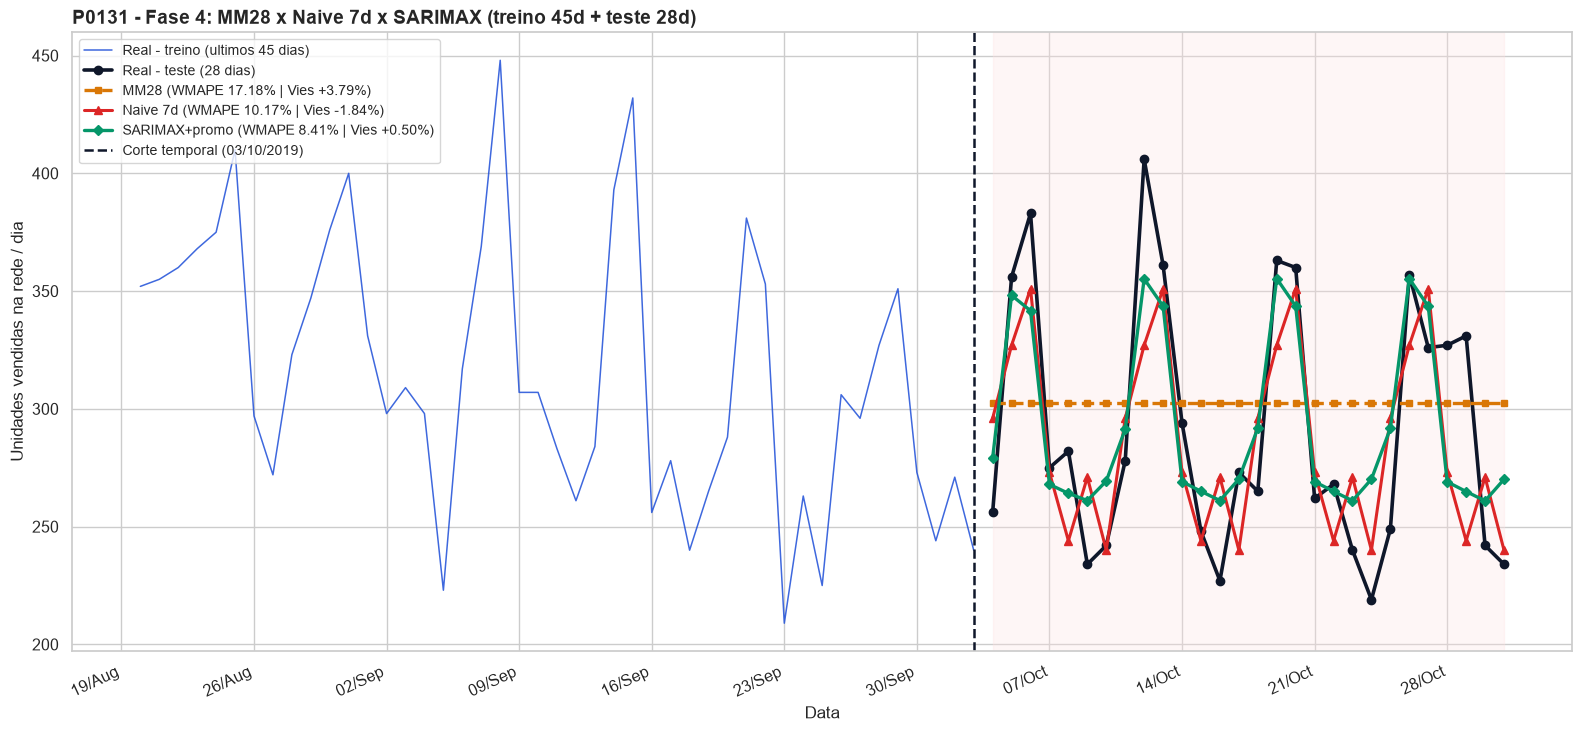

Figura salva em: C:\Users\flavi\Documents\GitHub\Supply-Chain-Forecasting\reports\figures\P0131_consolidado_mm28_naive7_sarimax.png


In [9]:
N_DIAS_VISIVEL = 45
fig, ax = plt.subplots(figsize=(16, 7.5))

zoom = serie_treino_ord.loc[serie_treino_ord.index.max() - pd.Timedelta(days=N_DIAS_VISIVEL - 1):]
ax.plot(zoom.index, zoom.values, color="#1D4ED8", linewidth=1.1, alpha=0.85,
        label="Real - treino (ultimos {} dias)".format(N_DIAS_VISIVEL))
ax.plot(indice_teste, real, color="#0F172A", marker="o", markersize=6, linewidth=2.6,
        label="Real - teste (28 dias)")
ax.plot(indice_teste, previsoes["Media Movel 28d (baseline comprador)"].values,
        color="#D97706", linewidth=2.4, linestyle="--", marker="s", markersize=5,
        label="MM28 (WMAPE {:.2f}% | Vies {:+.2f}%)".format(w_mm28, v_mm28))
ax.plot(indice_teste, previsoes["Naive Sazonal (ultimos 7d)"].values,
        color="#DC2626", linewidth=2.2, marker="^", markersize=5.5,
        label="Naive 7d (WMAPE {:.2f}% | Vies {:+.2f}%)".format(w_naive, v_naive))
ax.plot(indice_teste, previsoes["SARIMAX (2,1,2)(1,1,1,7) + promo"].values,
        color="#059669", linewidth=2.4, marker="D", markersize=5,
        label="SARIMAX+promo (WMAPE {:.2f}% | Vies {:+.2f}%)".format(w_sarimax, v_sarimax))

ax.axvline(x=data_corte, color="#0F172A", linestyle="--", linewidth=1.8,
           label="Corte temporal ({:%d/%m/%Y})".format(data_corte))
ax.axvspan(data_inicio_teste, data_maxima, color="#FEE2E2", alpha=0.30)

ax.set_title("{} - Fase 4: MM28 x Naive 7d x SARIMAX (treino 45d + teste 28d)".format(PRODUTO_FOCO),
             fontsize=13.5, fontweight="bold", loc="left")
ax.set_ylabel("Unidades vendidas na rede / dia")
ax.set_xlabel("Data")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%b"))
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
ax.legend(loc="upper left", fontsize=9.8)
plt.tight_layout()
caminho_fig = os.path.join(PASTA_FIGURAS, "{}_consolidado_mm28_naive7_sarimax.png".format(PRODUTO_FOCO))
plt.savefig(caminho_fig, dpi=160, bbox_inches="tight", facecolor="white")
plt.show()
print("Figura salva em: {}".format(caminho_fig))

## Conclusão da Fase 4
Na janela única de holdout o SARIMAX+promo é o melhor modelo em precisão e em viés, mas
**uma única janela não sustenta uma promessa ao comitê**. A Fase 5 repete a avaliação em
12 origens móveis para verificar se o desempenho se mantém ao longo do tempo.